# Actividad | Dataset
Esta actividad busca generar un proyecto de Machine Learning End-to-End. El conjunto de datos elegido para la actividad es el conjunto Adults(https://archive.ics.uci.edu/dataset/2/adult) de la Universidad de California en Irvine

## 1 Carga y Descripción del dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import mlflow
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score


In [2]:
# fetch dataset 
adult = fetch_ucirepo(id=2) 
  
# data (as pandas dataframes) 
X = adult.data.features 
y = adult.data.targets 

In [3]:
y.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   income  48842 non-null  str  
dtypes: str(1)
memory usage: 624.7 KB


In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
dtypes: int64(6), str(8)
memory usage: 8.7 MB


Este dataset viene dividido desde el origen, cuenta con **48842** registros totales. La variable a predecir(y) es **income**, esta indica si los ingresos del individuo son mayores o, menores o iguales a 50k dólares; no tiene valores faltantes, y es de tipo categórica binaria que puede tomar los valores: >50K, <=50K. Las variables predictoras(X) se describen a continuación:
* **age**: Edad del individuo. Continua. 0 registros faltantes.
* **workclass**: Clase o sector de empleo al que pertenece la persona (ej. privado, gobierno, cuenta propia). Categórica. Sí contiene registros faltantes (comúnmente representados con "?").
* **fnlwgt**: Peso final (final weight), una estimación demográfica del censo sobre a cuántas personas de la población general representa ese registro específico. Continua. 0 registros faltantes.
* **education**: Nivel más alto de educación formal alcanzado. Categórica. 0 registros faltantes.
* **education-num**: Nivel de educación expresado como un valor numérico (donde un número mayor equivale a un mayor nivel educativo). Continua. 0 registros faltantes.
* **marital-status**: Estado civil actual del individuo. Categórica. 0 registros faltantes.
* **occupation**: Tipo de ocupación, oficio o profesión que desempeña. Categórica. Sí contiene registros faltantes (comúnmente representados con "?").
* **relationship**: Relación o rol de la persona dentro de su estructura o núcleo familiar (ej. esposo, hijo, no familiar). Categórica. 0 registros faltantes.
* **race**: Raza o grupo étnico del individuo. Categórica. 0 registros faltantes.
* **sex**: Sexo del individuo. Categórica. 0 registros faltantes.
* **capital-gain**: Ganancias de capital financiero reportadas por el individuo en dólares. Continua. 0 registros faltantes.
* **capital-loss**: Pérdidas de capital financiero reportadas en dólares. Continua. 0 registros faltantes.
* **hours-per-week**: Número de horas promedio trabajadas por semana. Continua. 0 registros faltantes.
* **native-country**: País de origen o nacimiento del individuo. Categórica. Sí contiene registros faltantes (comúnmente representados con "?").

## 2 EDA

In [5]:
X.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


Vemos que hay outliers en todas las variables predictoras numéricas excepto en education num, donde parece que no es tan alejado el valor máximo.

In [6]:
X.isnull().sum()

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
dtype: int64

Observamos la cantidad exacta de valores faltantes que tenemos en el dataset, tenemos 2799 en workclass, 2809 en occupation y 857 en native-country. Si quisieramos eliminar los registros completos suponiendo que a los mismos registros a los que les falta occupation también les faltan workclass y native-country estaríamos eliminando alrededor de 6% de los datos.

In [7]:
# Se juntan X y Y para visualizar las relaciones entre X y Y
df = pd.concat([X, y], axis=1)

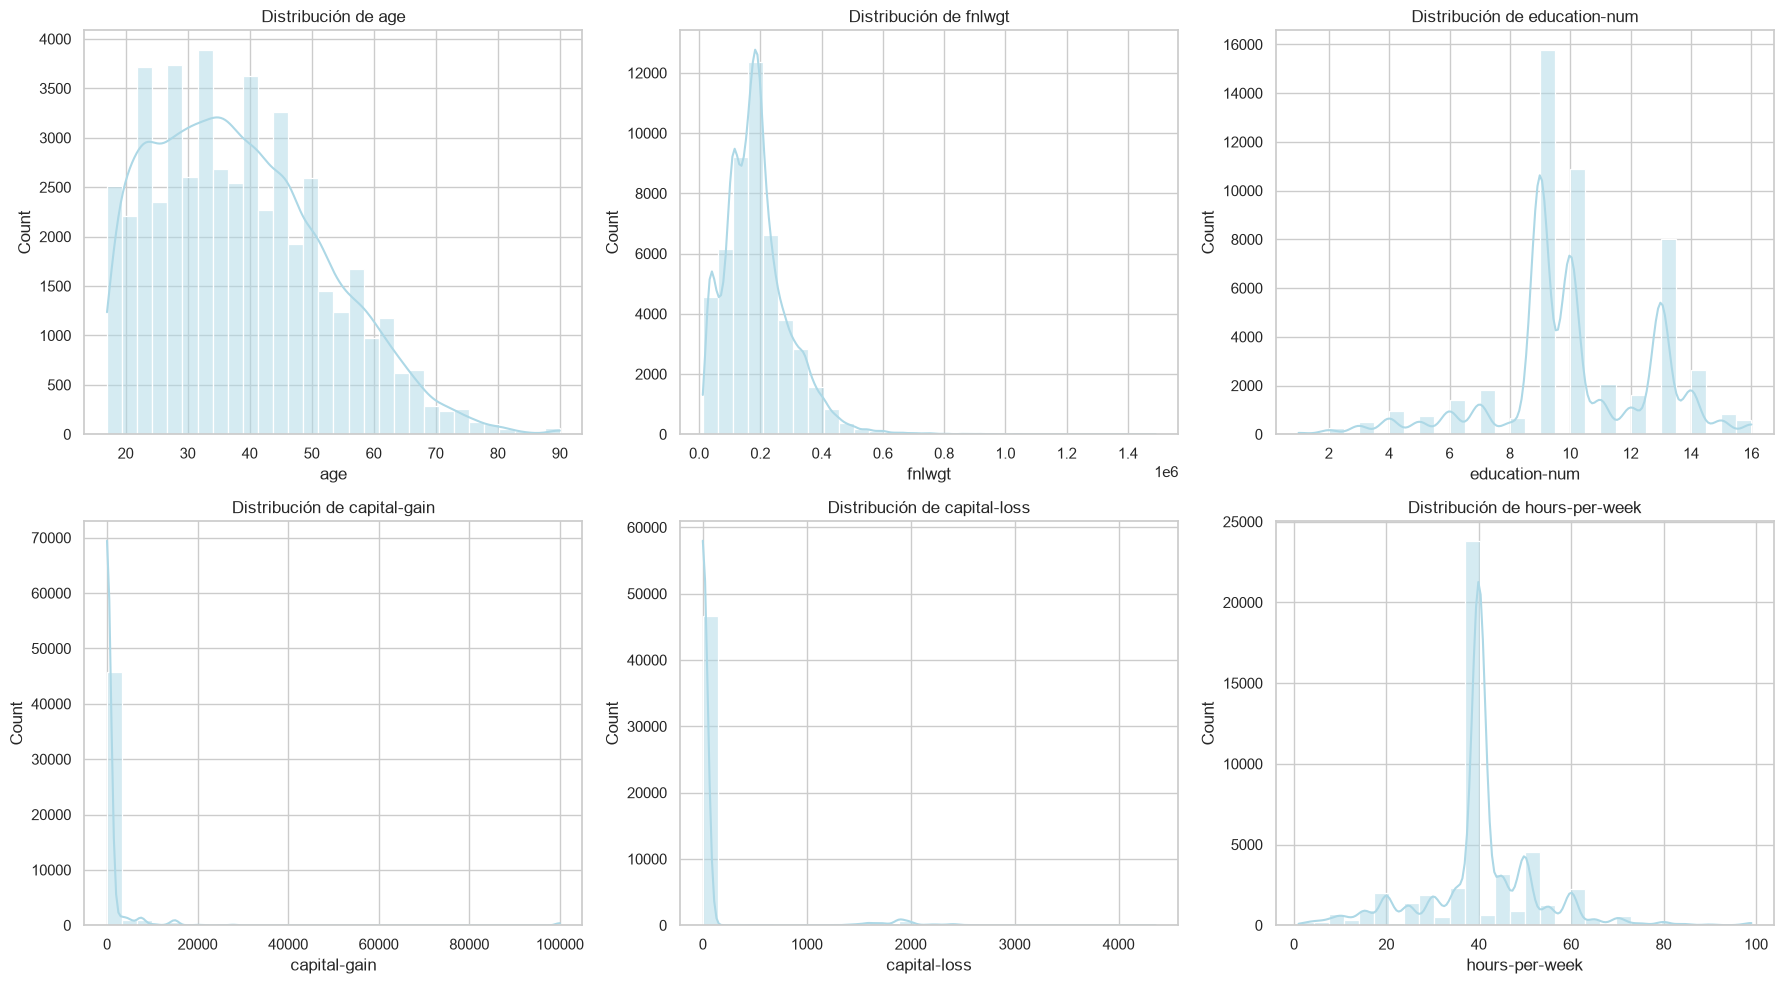

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\1668335896.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df, palette='viridis')


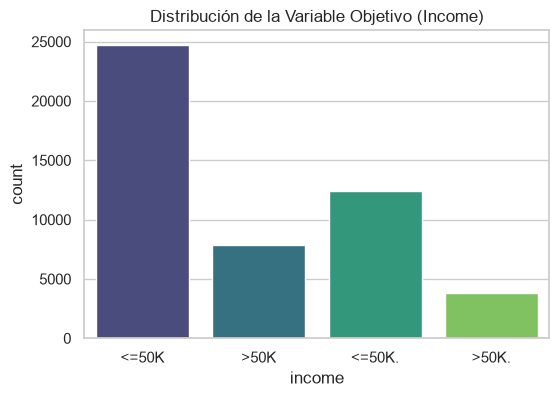

In [8]:
sns.set_theme(style="whitegrid")

# distribucion de variables numericas
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i//3, i%3], color='lightblue')
    axes[i//3, i%3].set_title(f'Distribución de {col}')

plt.tight_layout()
plt.show()

# Distribución de variable objetivo
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='viridis')
plt.title('Distribución de la Variable Objetivo (Income)')
plt.show()

Con estas nuevas visualizaciones se pueden notar irregularidades en la distribución de todas las variables numéricas. Education-num y hours-per-week son las únicas variables que parecen tener una distribución medianamente normal. Las variables capital-gain, fnlwgt, capital-loss y age presentan sesgo a la izquierda esto significa diferentes cosas para cada tabla. Para age signica que la mayoría de las personas en la base de datos son menores de 50 años. Para capital-gain signica que solo una fracción muy pequeña de la población tiene ganancias, y unos pocos individuos tienen ganancias muy altas. Mientras que capital-loss significa que la mayor parte de la población no tiene pérdidas. Finalmente para fnlwgt la gráfica que se ve significa que la mayoría de los registros tienen pesos demográficos relativamente bajos a medios, pero hay unos pocos registros con pesos muy altos.

Con el gráfico de barras que hicimos logramos visualizar algo interesante, en primer lugar notamos que hay que corregir los valores de la variable a predecir, dado que tiene dos tipos de escritura para etiquetas con el mismo significado. Además se puede ver que más de 35,000 individuos de nuestra población de 48,842 registran ingresos menores a 50k.

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\977484032.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='age', data=df, palette='Set2')


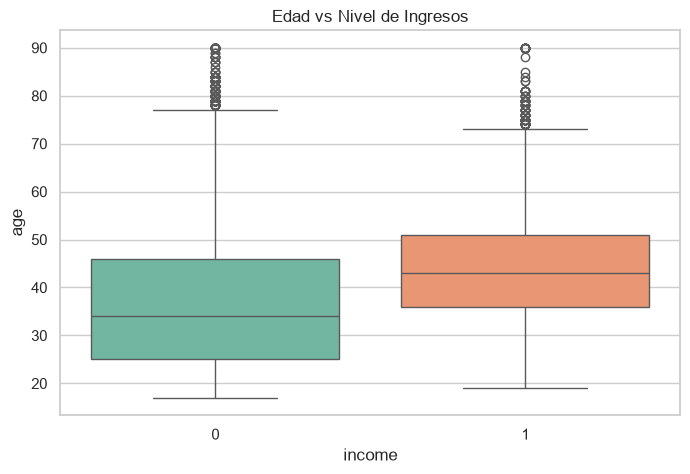

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\977484032.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='hours-per-week', data=df, palette='Set2')


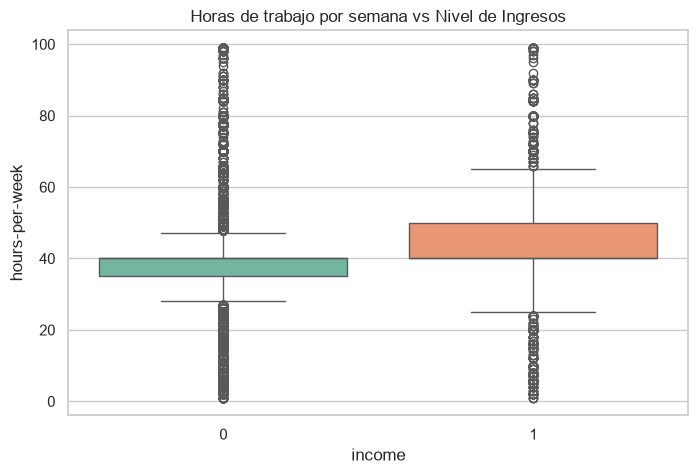

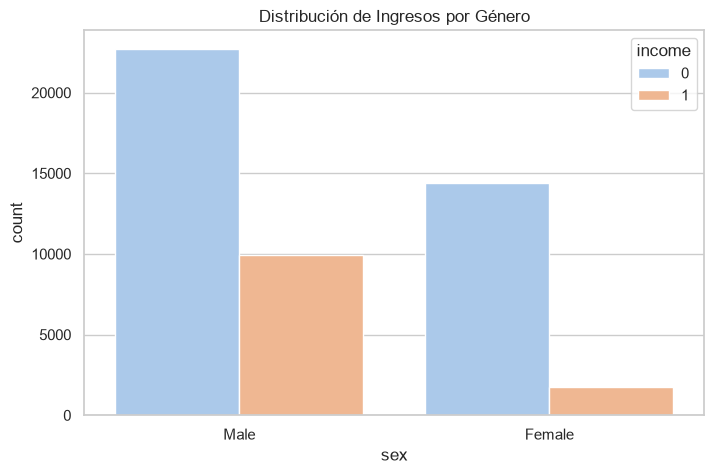

In [9]:
# Correcion de etiquetas, pasaremos de una vez a binario con el reemplazo:
df['income'] = df['income'].replace({"<=50K": int(0), "<=50K.": int(0), ">50K": int(1), ">50K.": int(1)})

# Edad vs Ingresos
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='age', data=df, palette='Set2')
plt.title('Edad vs Nivel de Ingresos')
plt.show()

# Horas por semana vs Ingresos
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='hours-per-week', data=df, palette='Set2')
plt.title('Horas de trabajo por semana vs Nivel de Ingresos')
plt.show()

# Género vs Ingresos
plt.figure(figsize=(8, 5))
sns.countplot(x='sex', hue='income', data=df, palette='pastel')
plt.title('Distribución de Ingresos por Género')
plt.show()

Se puede notar que en general para la variable edad, tanto en la población con ingresos mayores a 50k, las edades mayores 75 años son consideradas como datos atípicos. En la gráfica "horas de trabajo vs nivel de ingresos" también podemos notar algo interesante para quienes ganan menos de 50k lo normal es trabajar entre 30 y 50 horas, mientras que para quienes ganan más de 50k pueden trabajar hasta alrededor de 60 horas. Fuera de esos rangos vemos valores atípicos y en ambos casos vemos que hay valores atípicos.

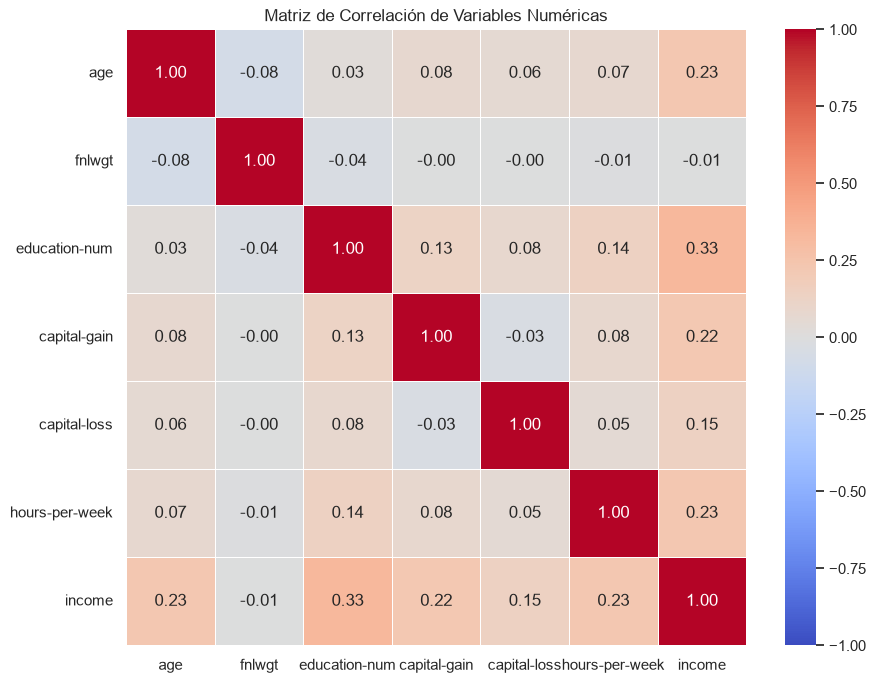

In [10]:
plt.figure(figsize=(10, 8))
# Calcular correlación de Pearson para variables numéricas
df['income'] = pd.to_numeric(df['income'])
corr = df.select_dtypes(include='number').corr()

# Generar un mapa de calor
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

No encontramos mucha relación entre las variables, por lo que realmente no hay necesidad de eliminar ninguna por correlación. Algo que se puede notar de esto es que la variable con menor correlación con income es fnlwgt
.

## 3 Limpieza de Datos

In [11]:
columnas_texto = df.select_dtypes(include=['object']).columns

for col in columnas_texto:
    df[col] = df[col].str.strip()

C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\2408607604.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df.select_dtypes(include=['object']).columns


Primero iniciamos la limpieza de espacios en blanco innecesarios en las columnas de texto. Además anteriormente se mencionó la existencia de valores faltantes identificables con ?, se procederá a hacer la imputación de valores faltantes con la moda(debido a que son categóricos)

In [12]:
# 1. Reemplazo infalible: busca el '?' ignorando cualquier espacio antes o después
df.replace('?', np.nan, inplace=True)

# 2. Comprobar cuántos nulos reales (NaN) se detectaron ahora
print("Nulos detectados antes de imputar:")
print(df.isnull().sum())

# 3. Rellenar los valores nulos con la moda de cada columna
for col in ['workclass', 'occupation', 'native-country']:
    moda_columna = df[col].mode()[0]
    df[col] = df[col].fillna(moda_columna)

# 4. Verificar que la imputación funcionó (debe salir 0 en todas)
print("\nNulos restantes tras la imputación:")
print(df.isnull().sum())



Nulos detectados antes de imputar:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
income               0
dtype: int64

Nulos restantes tras la imputación:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


Realmente ya eliminamos nuestra mayor preocupación, que eran los valores nulos, a través de la imputación a la tabla con la moda. Actualmente nos faltaría verificar si hay registros duplicados y eliminarlos si hay. También se va a eliminar education ya que es una columna redundante, se hará one hot encoding y escalamiento.

In [13]:
print(f"Filas antes de eliminar duplicados: {df.shape[0]}")
df.drop_duplicates(inplace=True)
print(f"Filas después de eliminar duplicados: {df.shape[0]}")

Filas antes de eliminar duplicados: 48842
Filas después de eliminar duplicados: 48789


In [14]:
# Eliminar la variable categórica de educación
df.drop('education', axis=1, inplace=True)
print(df.columns)

Index(['age', 'workclass', 'fnlwgt', 'education-num', 'marital-status',
       'occupation', 'relationship', 'race', 'sex', 'capital-gain',
       'capital-loss', 'hours-per-week', 'native-country', 'income'],
      dtype='str')


Al eliminar duplicados nos quedamos con 53 registros menos y al eliminar la columna education pasamos a tener un total de 14 columnas en total. Como vimos un sesgo muy alto en las columnas capital-gain y capital-loss podemos aplicarles transformaciones logarítmicas a ambas para que el modelo obtenga mejor información de ellas.

In [15]:
df['capital-gain'] = np.log1p(df['capital-gain'])
df['capital-loss'] = np.log1p(df['capital-loss'])

Ahora se pasa a hacer one-hot-encoding de las variables, es importante recordar que actualmente tenemos 14 columnas en total incluyendo la variable predictora. Al hacer OHE pasaremos a tener muchas más debido a las columnas como workclass(que tiene 8 categorías) y native-country(que tiene 41 categorías).

In [16]:
columnas_categoricas = df.select_dtypes(include=['object']).columns
print("Columnas categoricas:", list(columnas_categoricas))

df_encoded = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True, dtype=int)

print(f"\nDimensiones originales: {df.shape}")
print(f"Dimensiones después de OHE: {df_encoded.shape}")


Columnas categoricas: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Dimensiones originales: (48789, 14)
Dimensiones después de OHE: (48789, 83)


C:\Users\aoran\AppData\Local\Temp\ipykernel_19388\1230753625.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_categoricas = df.select_dtypes(include=['object']).columns


## 4 Entrenamiento de modelo base

Pasamos de 14 columnas a 82. Son 82 columnas las que ayudarían a predecir el la variable objetivo, considero que aunque solo es un ejercicio de práctica dar tantas variables puede resultar innecesario por lo que se aplicará un PCA que ayudará a disminuir la carga para el modelo. Para esto primero separaremos en train y test(para evitar data leakage) y escalaremos los datos para que todos tengan el mismo peso al momento de hacer la predicción

In [17]:
X = df_encoded.drop('income', axis=1)
y = df_encoded['income']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Escalamos datos 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA y buscamos tener por lo menos 90% de la información original
pca = PCA(n_components=0.90, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Columnas originales antes de PCA: {X_train_scaled.shape[1]}")
print(f"Nuevas columnas (Componentes) después de PCA: {X_train_pca.shape[1]}")
print(f"Información conservada: {sum(pca.explained_variance_ratio_) * 100:.2f}%")

Columnas originales antes de PCA: 82
Nuevas columnas (Componentes) después de PCA: 65
Información conservada: 90.84%


Probablemente debido al escalamiento que hicimos es que nos quedamos con tantas columnas después del PCA, sin embargo no está mal reducción que se hizo. Ahora que tenemos los datos nuevos vamos a entrenar un modelo de regresión logística que nos permitirá tener un baseline.

In [18]:
params = {
    "random_state": 42,
    "class_weight": "balanced",
    "solver": "liblinear"
}
LR = LogisticRegression(**params)

LR.fit(X_train_pca, y_train)

y_pred = LR.predict(X_test_pca)
y_pred_proba = LR.predict_proba(X_test_pca)[:, 1]

Se realizó el entrenamiento del modelo baseline con los datos del PCA y una serie de parámetros base que fueron almacenados en un diccionario para mayor facilidad al momento de registrar los parámetros del experimento en MLflow

## 5 Evaluación del modelo

Con el dataset que tenemos queremos predecir si alguien tiene ingresos menores o mayores a 50k basandonos en las variables predictoras.  Estamos buscando predecir la clase minoritaria especialmente por lo que escogen las métricas: precisión, exhaustividad, f1_score y roc_auc.

In [19]:
# 3. Calcular las métricas enfocándonos en la clase positiva (1: >50K)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Mostrar los resultados
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

Precision: 0.5434
Recall:    0.8421
F1-Score:  0.6606
ROC AUC:   0.8949


Los resultados del modelo muestran un AUC muy alto que siginifaca que existe una buena probabilidad de que clasifique correctamente a dos personas si las escoges al azar. También se detectó una tasa de recall alta, lo que significa que es bueno detectando falsos negativos(ingresos mayores a 50k). Se encontró también una tasa baja de precisión, esto quiere decir que tiene una tasa alta de falsos positivos, prácticamente adivinó a las personas ue ganan más de 50k. Finalmente el f1-score muestra que el modelo es mejor que adivinar considerando una probabilidad de 50-50 pero peor considerando que la proporción de la distribución es cercana a 70-30.

## 6 Registro del modelo en MLflow

Ya que se calcularon las métricas podemos pasar todo a MLflow, aunque realmente eso se podía hacer desde que se inició el entrenamiento

In [20]:
metrics = {
    "Precision": precision,
    "F1-score": f1,
    "Recall": recall,
    "ROC AUC": roc_auc
}

# En lugar de apuntar a sqlite, apuntas al servidor web local
mlflow.set_tracking_uri("http://127.0.0.1:8080")
mlflow.set_experiment("Clasificacion_Adult")

with mlflow.start_run(run_name="LR_base"):
    mlflow.log_params(params)
    mlflow.sklearn.log_model(LR, input_example=X_train_pca)

    mlflow.log_metrics(metrics)




2026/10/04 23:27:42 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\aoran\Desktop\Maestría\4to trimestre\MLOps\Semana 3
2026/10/04 23:27:48 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in c:\Users\aoran\Desktop\Maestría\4to trimestre\MLOps\Semana 3
2026/10/04 23:27:48 INFO mlflow.utils.environment: Detected uv project at c:\Users\aoran\Desktop\Maestría\4to trimestre\MLOps\Semana 3. Attempting to export requirements via 'uv export'.
2026/10/04 23:27:48 WARNING mlflow.utils.uv_utils: uv is not available or version is below minimum required. Falling back to pip-based inference.
2026/10/04 23:27:48 WARNING mlflow.utils.environment: uv export failed or returned no requirements. Falling back to package capture based inference.
2026/10/04 23:27:57 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run LR_base at: http://127.0.0.1:8080/#/experiments/3/runs/f8443b3b106840bbb0238fed4215817f
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/3


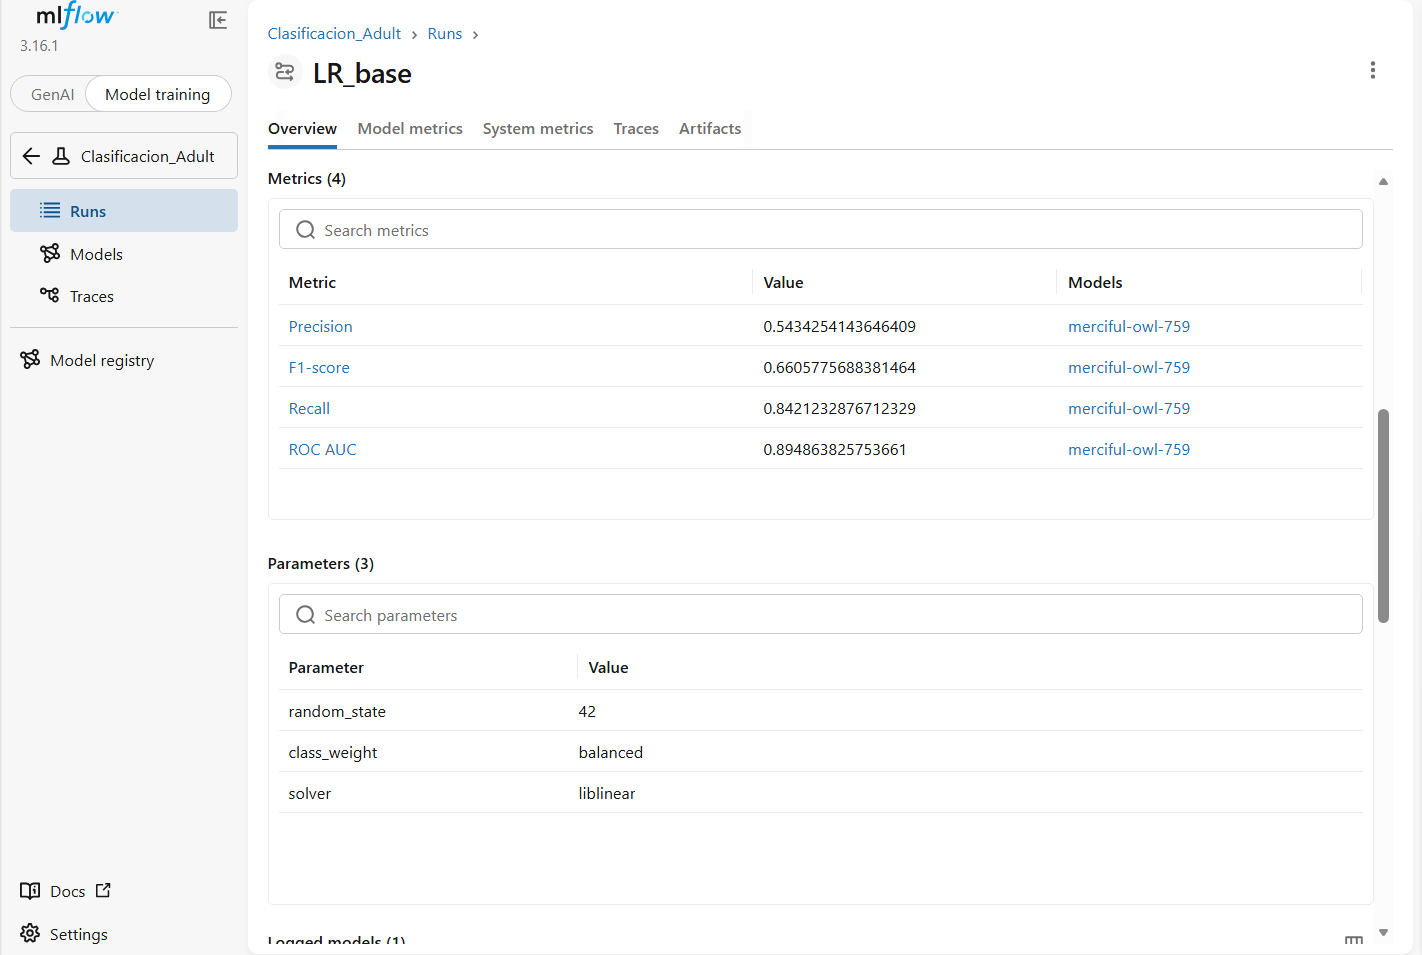

## 7 Reflexión

Las práticas de MLOps podrían mejorar este proyecto haciéndolo más reproducible y dandole un mejor seguimiento a todos los pasos por los que pasa el proyecto. Algunas de las cosas que se le puede agregar es reproducibilidad de los datos, aunque sí se les agrego donde era necesario random state, se puede también hacer seguimiento de los datos para que puedan usarse los datos exactos siempre y podamos ver como es que los hemos cambiado conforme pasan diferentes etapas del proyecto. Añadir pipelines también sería una buena forma de mejorar el proyecto, dado que estos automatizarían secciones del proyecto que facilitarían procesos. Dentro del área en la que me desarrollo actualmente se usa más DevOps, pero me parece que podría verse beneficiada de una parte específica de MLops y es del versionado de datos, dado que actualmente me dedico a Ingeniería de datos rara vez toco modelos de ML, sin embargo creo que justamente el área de MLops es lo que me ha estado faltando para dar pasos más encaminados al área profesional que más me interesa.
